# 鶏の歩行能力・加速度データの概要確認

## 目的

鶏の歩行能力と加速度データについて、
データ構造、個体数、欠損値、各変数の内容を確認する。

また、WalkingAbilityと個体属性・行動データとの関係を探索し、
以降の前処理・特徴量分析で使用するデータを整理する。

In [3]:
import pandas as pd

# データの読み込み
df = pd.read_csv("../data/raw/walking_welfare.csv")

# データサイズ
print("データサイズ:", df.shape)

# 最初の5行
display(df.head())

データサイズ: (2497, 120)


,Pen_Bird_Strain_Date,Age_Days,SexFM,Repeated_Weightkg,Welfare_Assess_weightkg,WalkingAbility,Feathercover,BreastplumageDirtiness,Pododermatitis,HockBurn,...,Z_Static_filt.Min,Z_Static_filt.Max,Z_Static_filt.AbsMean,Z_Static_filt.IQR,Z_Static_filt.Skewness,Z_Static_filt.Kurtosis,Z_Static_filt.Entropy,Z_Static_filt.Peak_Trough.x,Z_Static_filt.Peak_Trough.y,UniqueBirds
0,11_4_NB_03.04.2019,48,M,2.078,2.491,1,0,0,0,0.5,...,-1.001594,-0.995931,0.999195,0.002326,0.525968,2.206204,5.703781,73.60555,-0.995930,Pen11_4_NB
1,11_4_NB_03.04.2019,48,M,2.078,2.491,1,0,0,0,0.5,...,-0.999236,-0.989803,0.994124,0.002721,-0.157488,2.480772,5.703779,38.75735,-0.989803,Pen11_4_NB
2,11_4_NB_03.04.2019,48,M,2.078,2.491,1,0,0,0,0.5,...,-1.000490,-0.989829,0.995626,0.005538,0.366600,1.888628,5.703777,296.67720,-0.989664,Pen11_4_NB
3,11_4_NB_03.04.2019,48,M,2.078,2.491,1,0,0,0,0.5,...,-0.999994,-0.991225,0.997022,0.001756,0.762005,3.187205,5.703781,47.47332,-0.990505,Pen11_4_NB
4,11_4_NB_03.04.2019,48,M,2.078,2.491,1,0,0,0,0.5,...,-0.999343,-0.992396,0.995572,0.003539,-0.267254,1.868994,5.703780,103.83390,-0.992396,Pen11_4_NB


In [4]:
# データの行数・列数
print("行数・列数:", df.shape)

# データ型や欠損の概要
df.info()

行数・列数: (2497, 120)
<class 'pandas.DataFrame'>
RangeIndex: 2497 entries, 0 to 2496
Columns: 120 entries, Pen_Bird_Strain_Date to UniqueBirds
dtypes: float64(103), int64(8), str(9)
memory usage: 2.3 MB


In [5]:
print("個体数:", df["UniqueBirds"].nunique())

個体数: 7


In [6]:
df["UniqueBirds"].value_counts()

UniqueBirds
Pen52_OO_R     1072
Pen51_3_NB      393
Pen11_4_NB      274
Pen22_1_NB      237
Pen12_BB_R      212
Pen21_PuB_H     186
Pen21_OO_H      123
Name: count, dtype: int64

## データの基本構造

- データ数：2,497行 × 120列
- 対象個体数：7羽
- 1個体につき複数行のデータが存在する
- 個体ごとのレコード数には大きな差があり、Pen52_OO_Rが最も多い
- 1行が具体的に何を表しているかは、Time.windowやDateなどを確認して判断する

## レコードの構造確認

1行が何を表しているのか確認するため、
個体・日付・時間窓・行動に関する変数を確認する。

In [8]:
cols = [
    "UniqueBirds",
    "Date",
    "Time.window",
    "Bird",
    "Pen",
    "Accel",
    "WalkingAbility",
    "MostFreq.Behaviour_1Si_2Sta_3Wa",
    "Prop.behaviour"
]

display(df[cols].head(20))

,UniqueBirds,Date,Time.window,Bird,Pen,Accel,WalkingAbility,MostFreq.Behaviour_1Si_2Sta_3Wa,Prop.behaviour
0,Pen11_4_NB,03.04.2019,100,4,Pen11,46167,1,1,1.000
1,Pen11_4_NB,03.04.2019,1000,4,Pen11,46167,1,1,1.000
2,Pen11_4_NB,03.04.2019,1001,4,Pen11,46167,1,1,1.000
3,Pen11_4_NB,03.04.2019,1002,4,Pen11,46167,1,1,1.000
4,Pen11_4_NB,03.04.2019,1003,4,Pen11,46167,1,1,0.697
5,Pen11_4_NB,03.04.2019,1005,4,Pen11,46167,1,1,0.670
6,Pen11_4_NB,03.04.2019,1006,4,Pen11,46167,1,1,1.000
7,Pen11_4_NB,03.04.2019,1007,4,Pen11,46167,1,1,1.000
8,Pen11_4_NB,03.04.2019,1008,4,Pen11,46167,1,1,1.000
9,Pen11_4_NB,03.04.2019,1009,4,Pen11,46167,1,1,1.000


### 時間窓と行動ラベルの確認

各レコードを区別している Time.window と、
行動を表す変数の値を確認する。

In [9]:
print("Time.window のユニーク数:",
      df["Time.window"].nunique())

print("最小値:", df["Time.window"].min())
print("最大値:", df["Time.window"].max())

display(
    df["Time.window"]
    .value_counts()
    .sort_index()
    .head(20)
)

Time.window のユニーク数: 1463
最小値: 2
最大値: 7122


Time.window
2     1
3     5
4     2
5     4
6     5
7     4
8     3
9     2
10    1
11    3
12    4
13    4
14    3
15    4
16    3
17    4
18    3
19    5
20    4
21    7
Name: count, dtype: int64

In [10]:
display(
    df["MostFreq.Behaviour_1Si_2Sta_3Wa"]
    .value_counts()
    .sort_index()
)

MostFreq.Behaviour_1Si_2Sta_3Wa
1    1865
2     333
3     299
Name: count, dtype: int64

### 確認結果

- Time.window は 1,463種類あり、値の範囲は2～7,122だった。
- 同一の Time.window が複数レコードに存在するため、単純なレコードIDではないと考えられる。
- 行動ラベルは Sitting・Standing・Walking の3種類で、全2,497レコードに設定されている。
- Sitting が1,865件と最も多く、Standing（333件）、Walking（299件）と比較してデータ数に偏りがある。
- 1行は、個体の特定の時間窓について行動と加速度特徴量を集計したレコードである可能性が高い。

In [11]:
print("WalkingAbility のユニーク数:",
      df["WalkingAbility"].nunique())

display(
    df["WalkingAbility"]
    .value_counts()
    .sort_index()
)

WalkingAbility のユニーク数: 2


WalkingAbility
1    1213
2    1284
Name: count, dtype: int64

In [12]:
display(
    df.groupby("UniqueBirds")[
        ["WalkingAbility", "Age_Days", "SexFM"]
    ].first()
)

,WalkingAbility,Age_Days,SexFM
UniqueBirds,,,
Pen11_4_NB,1,48,M
Pen12_BB_R,2,26,M
Pen21_OO_H,1,48,F
Pen21_PuB_H,1,48,F
Pen22_1_NB,1,48,F
Pen51_3_NB,1,48,M
Pen52_OO_R,2,27,M


### WalkingAbility の確認結果

- WalkingAbility は1・2の2種類で構成されている。
- レコード数では1が1,213件、2が1,284件で、ほぼ均等である。
- 一方、個体単位では WalkingAbility=1 が5羽、WalkingAbility=2 が2羽である。
- WalkingAbility=2 の2羽は26～27日齢、WalkingAbility=1 の5羽はすべて48日齢だった。
- そのため、WalkingAbilityと加速度特徴量の関係を分析する際には、年齢による影響と歩行能力による影響を区別できない可能性がある。
- また、同一個体から多数のレコードが取得されているため、各レコードを独立した個体として扱わないよう注意する。

## 個体属性・福祉指標の確認

対象となる7個体について、年齢・性別・品種・体重・
WalkingAbility・その他の福祉指標を確認する。

In [13]:
bird_cols = [
    "UniqueBirds",
    "Age_Days",
    "SexFM",
    "Strain",
    "Repeated_Weightkg",
    "Welfare_Assess_weightkg",
    "WalkingAbility",
    "Feathercover",
    "BreastplumageDirtiness",
    "Pododermatitis",
    "HockBurn",
    "LegStraightnessLeft",
    "LegStraightnessRight"
]

bird_summary = (
    df[bird_cols]
    .drop_duplicates()
    .sort_values("UniqueBirds")
)

display(bird_summary)

,UniqueBirds,Age_Days,SexFM,Strain,Repeated_Weightkg,Welfare_Assess_weightkg,WalkingAbility,Feathercover,BreastplumageDirtiness,Pododermatitis,HockBurn,LegStraightnessLeft,LegStraightnessRight
0,Pen11_4_NB,48,M,NB,2.078,2.491,1,0,0,0,0.5,B1,B1
185,Pen11_4_NB,26,M,NB,0.759,2.491,1,0,0,0,0.5,B1,B1
274,Pen12_BB_R,26,M,R,1.407,2.568,2,1,1,0,0.5,B1,B1
486,Pen21_OO_H,48,F,H,1.937,1.937,1,0,1,0,0.5,B1,B1
514,Pen21_OO_H,26,F,H,0.790,1.937,1,0,1,0,0.5,B1,B1
569,Pen21_OO_H,40,F,H,1.569,1.937,1,0,1,0,0.5,B1,B1
609,Pen21_PuB_H,48,F,H,2.237,2.237,1,0,1,0,0.5,0,0
730,Pen21_PuB_H,40,F,H,1.810,2.237,1,0,1,0,0.5,0,0
795,Pen22_1_NB,48,F,NB,1.843,2.198,1,0,0,0,0.5,0,0
858,Pen22_1_NB,26,F,NB,0.733,2.198,1,0,0,0,0.5,0,0


In [14]:
bird_age_summary = (
    df.groupby(["UniqueBirds", "Age_Days"])
      .agg(
          Sex=("SexFM", "first"),
          Strain=("Strain", "first"),
          WalkingAbility=("WalkingAbility", "first"),
          Weight=("Repeated_Weightkg", "first"),
          Feathercover=("Feathercover", "first"),
          Pododermatitis=("Pododermatitis", "first"),
          HockBurn=("HockBurn", "first"),
          Records=("Time.window", "count")
      )
      .reset_index()
)

display(bird_age_summary)

,UniqueBirds,Age_Days,Sex,Strain,WalkingAbility,Weight,Feathercover,Pododermatitis,HockBurn,Records
0,Pen11_4_NB,26,M,NB,1,0.759,0,0,0.5,89
1,Pen11_4_NB,48,M,NB,1,2.078,0,0,0.5,185
2,Pen12_BB_R,26,M,R,2,1.407,1,0,0.5,212
3,Pen21_OO_H,26,F,H,1,0.790,0,0,0.5,55
4,Pen21_OO_H,40,F,H,1,1.569,0,0,0.5,40
5,Pen21_OO_H,48,F,H,1,1.937,0,0,0.5,28
6,Pen21_PuB_H,40,F,H,1,1.810,0,0,0.5,65
7,Pen21_PuB_H,48,F,H,1,2.237,0,0,0.5,121
8,Pen22_1_NB,26,F,NB,1,0.733,0,0,0.5,67
9,Pen22_1_NB,40,F,NB,1,1.478,0,0,0.5,107


In [15]:
display(
    pd.crosstab(
        df["UniqueBirds"],
        df["WalkingAbility"]
    )
)

WalkingAbility,1,2
UniqueBirds,,
Pen11_4_NB,274,0
Pen12_BB_R,0,212
Pen21_OO_H,123,0
Pen21_PuB_H,186,0
Pen22_1_NB,237,0
Pen51_3_NB,393,0
Pen52_OO_R,0,1072


### 個体属性を確認して分かったこと

- 対象は7個体で、一部の個体は複数の日齢で繰り返し測定されている。
- WalkingAbility=1は5個体、WalkingAbility=2は2個体だった。
- WalkingAbility=2はPen12_BB_RとPen52_OO_Rのみで、両個体ともStrain=Rだった。
- WalkingAbilityと個体・Strainなどの属性が強く結び付いているため、
  WalkingAbilityによる差を単純に歩行能力だけの影響と解釈することは難しい。
- 複数日齢のデータを持つ個体では、成長に伴う体重・行動・加速度特徴量の変化を分析できる可能性がある。

## behaviour_welfare データの確認

walking_welfare 以外のデータセットについて、
データ数・変数・個体数を確認する。

WalkingAbilityと実際の行動時間との関係を確認し、
加速度特徴量の分析方針を検討する。

In [17]:
behaviour_df = pd.read_excel(
    "../data/raw/behaviour_welfare.xlsx"
)

print("データサイズ:", behaviour_df.shape)

display(behaviour_df.head())

データサイズ: (4590, 24)


,Bird_Pen_Strain_Date_Time,Bird,Pen,Strain,Age_Days,Tiers,Total_Duration_Sec,Frequency,Average_BoutLength,SexFM,...,BreastplumageDirtiness,Pododermatitis,HockBurn,LegStraightnessLeft,LegStraightnessRight,PerTimeAct,Pen_Bird_Strain_Date,Pen_Bird_Strain_Date_Accel,Date,Time
0,1_11_NB_03.04.2019_11.40-12.20,1,11,NB,48,Drink_Standing,0.0,0,0.0,M,...,0,0,0.5,B1,B1,18.135498,11_1_NB_03.04,Pen11_1_NB_03.04.2019_46163,03.04.2019,11.40-12.20
1,1_11_NB_03.04.2019_11.40-12.20,1,11,NB,48,Self-Peck_Mark,0.0,0,0.0,M,...,0,0,0.5,B1,B1,18.135498,11_1_NB_03.04,Pen11_1_NB_03.04.2019_46163,03.04.2019,11.40-12.20
2,1_11_NB_03.04.2019_11.40-12.20,1,11,NB,48,Running,0.0,0,0.0,M,...,0,0,0.5,B1,B1,18.135498,11_1_NB_03.04,Pen11_1_NB_03.04.2019_46163,03.04.2019,11.40-12.20
3,1_11_NB_03.04.2019_11.40-12.20,1,11,NB,48,Sidelying_Inactive,0.0,0,0.0,M,...,0,0,0.5,B1,B1,18.135498,11_1_NB_03.04,Pen11_1_NB_03.04.2019_46163,03.04.2019,11.40-12.20
4,1_11_NB_03.04.2019_11.40-12.20,1,11,NB,48,Wing_flap,0.0,0,0.0,M,...,0,0,0.5,B1,B1,18.135498,11_1_NB_03.04,Pen11_1_NB_03.04.2019_46163,03.04.2019,11.40-12.20


In [18]:
print("行動の種類数:", behaviour_df["Tiers"].nunique())

display(
    behaviour_df["Tiers"]
    .value_counts()
)

print("Bird数:", behaviour_df["Bird"].nunique())

print("Pen数:", behaviour_df["Pen"].nunique())

行動の種類数: 34


Tiers
Drink_Standing        135
Self-Peck_Mark        135
Running               135
Sidelying_Inactive    135
Wing_flap             135
Preen_Sitting         135
Play_Fight            135
Walking               135
Peck_beak             135
Stand_Inactive        135
Preen_Standing        135
Peck_Accel            135
Reverse_Behaviour     135
Headshake             135
Wing_assisted_run     135
Shuffle               135
Dust_Bathing          135
Foraging              135
Sit_Inactive          135
Head_Scratch          135
Self-Peck_Accel       135
Feather_peck          135
Feather_Ruffle        135
Out_of_View           135
Feed_sitting          135
Perch                 135
Peck_wall             135
Leg&Wing_Stretch      135
Crawling              135
Peck_litter           135
Preen_Sidelying       135
Peck_perch            135
Hop/Jump              135
Feed_Standing         135
Name: count, dtype: int64

Bird数: 10
Pen数: 11


In [19]:
for col in behaviour_df.columns:
    print(col)

Bird_Pen_Strain_Date_Time
Bird
Pen
Strain
Age_Days
Tiers
Total_Duration_Sec
Frequency
Average_BoutLength
SexFM
Repeated_Weightkg
Welfare_Assess_weightkg
WalkingAbility
Feathercover
BreastplumageDirtiness
Pododermatitis
HockBurn
LegStraightnessLeft
LegStraightnessRight
PerTimeAct
Pen_Bird_Strain_Date
Pen_Bird_Strain_Date_Accel
Date
Time


In [20]:
print(
    "Pen_Bird_Strain_Date のユニーク数:",
    behaviour_df["Pen_Bird_Strain_Date"].nunique()
)

display(
    behaviour_df[
        ["Pen_Bird_Strain_Date", "Bird", "Pen",
         "Strain", "Age_Days", "SexFM",
         "WalkingAbility"]
    ]
    .drop_duplicates()
    .sort_values(["Pen", "Bird", "Age_Days"])
)

Pen_Bird_Strain_Date のユニーク数: 135


,Pen_Bird_Strain_Date,Bird,Pen,Strain,Age_Days,SexFM,WalkingAbility
34,11_1_NB_12.03,1,11,NB,26,M,1
0,11_1_NB_03.04,1,11,NB,48,M,1
102,11_2_NB_12.03,2,11,NB,26,M,1
136,11_2_NB_26.03,2,11,NB,40,M,1
68,11_2_NB_03.04,2,11,NB,48,M,1
...,...,...,...,...,...,...,...
4420,63_OP_R_13.03,OP,63,R,27,F,2
4454,63_OP_R_16.03,OP,63,R,30,F,2
4488,63_PB_R_13.03,PB,63,R,27,F,3
4522,63_PB_R_16.03,PB,63,R,30,F,3


In [21]:
print(
    "Bird_Pen_Strain_Date_Time のユニーク数:",
    behaviour_df["Bird_Pen_Strain_Date_Time"].nunique()
)

display(
    behaviour_df[
        ["Bird_Pen_Strain_Date_Time",
         "Pen_Bird_Strain_Date",
         "Bird", "Pen", "Age_Days"]
    ]
    .drop_duplicates()
    .head(20)
)

Bird_Pen_Strain_Date_Time のユニーク数: 135


,Bird_Pen_Strain_Date_Time,Pen_Bird_Strain_Date,Bird,Pen,Age_Days
0,1_11_NB_03.04.2019_11.40-12.20,11_1_NB_03.04,1,11,48
34,1_11_NB_12.03.2019_12.10-12.50,11_1_NB_12.03,1,11,26
68,2_11_NB_03.04.2019_11.40-12.20,11_2_NB_03.04,2,11,48
102,2_11_NB_12.03.2019_12.10-12.50,11_2_NB_12.03,2,11,26
136,2_11_NB_26.03.2019_11.45-12.30,11_2_NB_26.03,2,11,40
170,3_11_NB_03.04.2019_11.40-12.20,11_3_NB_03.04,3,11,48
204,3_11_NB_12.03.2019_12.10-12.50,11_3_NB_12.03,3,11,26
238,3_11_NB_26.03.2019_11.45-12.30,11_3_NB_26.03,3,11,40
272,4_11_NB_03.04.2019_11.40-12.20,11_4_NB_03.04,4,11,48
306,4_11_NB_12.03.2019_12.10-12.50,11_4_NB_12.03,4,11,26


In [23]:
obs_df = (
    behaviour_df[
        ["Pen_Bird_Strain_Date", "Bird", "Pen", "Strain",
         "Age_Days", "SexFM", "WalkingAbility"]
    ]
    .drop_duplicates()
)

print("観測数:", len(obs_df))

display(
    obs_df["WalkingAbility"]
    .value_counts()
    .sort_index()
)

観測数: 135


WalkingAbility
0     8
1    82
2    40
3     5
Name: count, dtype: int64

In [24]:
display(
    obs_df.groupby("WalkingAbility")
    .agg(
        観測数=("Pen_Bird_Strain_Date", "count"),
        Pen数=("Pen", "nunique")
    )
)

,観測数,Pen数
WalkingAbility,,
0,8,3
1,82,9
2,40,8
3,5,2


In [25]:
walking = behaviour_df[
    (behaviour_df["Tiers"] == "Walking") &
    (behaviour_df["WalkingAbility"].isin([1, 2]))
].copy()

display(
    walking.groupby("WalkingAbility")[
        ["Total_Duration_Sec", "Frequency", "Average_BoutLength"]
    ].agg(["count", "mean", "median", "std"])
)

Total_Duration_Sec                               Frequency  \
                            count       mean  median        std     count   
WalkingAbility                                                              
1                              82  29.655902  27.519  19.138032        82   
2                              40  20.241425  15.485  17.555688        40   

                                          Average_BoutLength            \
                    mean median       std              count      mean   
WalkingAbility                                                           
1               8.109756    7.0  5.307823                 82  3.640603   
2               6.150000    5.5  4.933143                 40  3.235419   

                                    
                  median       std  
WalkingAbility                      
1               3.422000  1.701747  
2               3.101136  1.369143

In [26]:
behaviour_12 = behaviour_df[
    behaviour_df["WalkingAbility"].isin([1, 2])
]

duration_compare = (
    behaviour_12
    .groupby(["Tiers", "WalkingAbility"])["Total_Duration_Sec"]
    .mean()
    .unstack()
)

duration_compare.columns = ["Ability_1", "Ability_2"]

duration_compare["Difference"] = (
    duration_compare["Ability_2"]
    - duration_compare["Ability_1"]
)

display(
    duration_compare
    .sort_values("Difference")
)

,Ability_1,Ability_2,Difference
Tiers,,,
Feed_Standing,28.462878,16.029650,-12.433228
Foraging,10.693378,0.526250,-10.167128
Walking,29.655902,20.241425,-9.414477
Out_of_View,19.749805,10.562775,-9.187030
Perch,6.536890,2.515750,-4.021140
Peck_litter,9.828671,6.135925,-3.692746
Stand_Inactive,35.089939,31.455125,-3.634814
Crawling,1.017024,0.530250,-0.486774
Drink_Standing,6.603463,6.350900,-0.252563


In [27]:
age_compare = (
    behaviour_12[
        behaviour_12["Tiers"].isin([
            "Walking",
            "Foraging",
            "Feed_Standing",
            "Preen_Sitting",
            "Sit_Inactive"
        ])
    ]
    .groupby(
        ["Age_Days", "WalkingAbility", "Tiers"]
    )["Total_Duration_Sec"]
    .mean()
    .unstack("WalkingAbility")
)

display(age_compare)

WalkingAbility                   1           2
Age_Days Tiers                                
26       Feed_Standing   10.999643   17.717222
         Foraging         3.865000    0.000000
         Preen_Sitting   22.246929   20.093889
         Sit_Inactive   160.825357  102.854444
         Walking         35.895143   29.037222
27       Feed_Standing   43.729455   20.610857
         Foraging         7.277727    0.000000
         Preen_Sitting   11.525727  132.713571
         Sit_Inactive   133.692545  656.872571
         Walking         35.378000   20.416143
30       Feed_Standing   18.424167    7.801429
         Foraging        14.645000    0.000000
         Preen_Sitting   21.154167   34.570286
         Sit_Inactive    99.457500  257.129000
         Walking         32.495000   21.694857
40       Feed_Standing   21.991500   11.887500
         Foraging        34.977000    2.687500
         Preen_Sitting   17.715300    0.302500
         Sit_Inactive   138.643900  295.521750
         Walking         30.944400   17.902500
41       Feed_Standing   32.624000    1.003333
         Foraging         4.712000    0.000000
         Preen_Sitting   11.372000   11.390000
         Sit_Inactive   192.676467  317.803333
         Walking         22.905333    8.703333
48       Feed_Standing   41.362889   23.228500
         Foraging         4.615833    1.030000
         Preen_Sitting    7.438167   17.023000
         Sit_Inactive   133.870278  200.806900
         Walking         27.458611   15.582500
49       Feed_Standing   16.823125         NaN
         Foraging        18.910875         NaN
         Preen_Sitting   26.471500         NaN
         Sit_Inactive   153.203125         NaN
         Walking         24.730625         NaN

Matplotlib is building the font cache; this may take a moment.


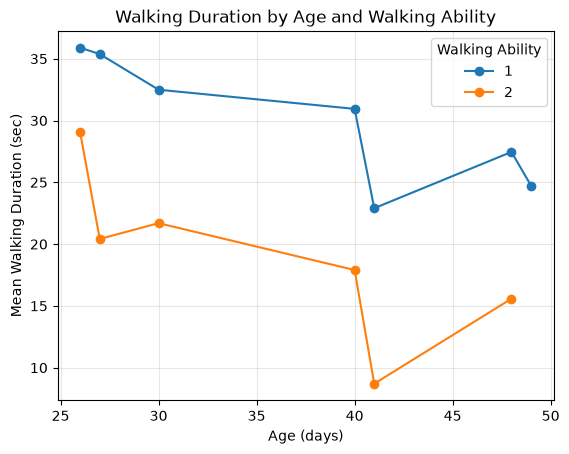

In [29]:
import matplotlib.pyplot as plt

walking_age = (
    behaviour_12[
        behaviour_12["Tiers"] == "Walking"
    ]
    .groupby(["Age_Days", "WalkingAbility"])["Total_Duration_Sec"]
    .mean()
    .unstack()
)

walking_age.plot(marker="o")

plt.xlabel("Age (days)")
plt.ylabel("Mean Walking Duration (sec)")
plt.title("Walking Duration by Age and Walking Ability")
plt.legend(title="Walking Ability")
plt.grid(alpha=0.3)

plt.show()

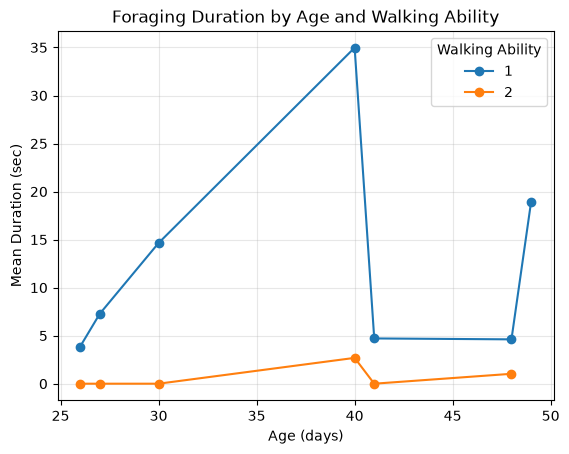

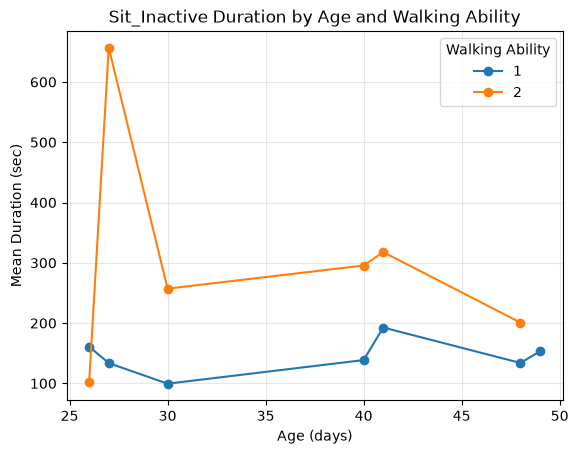

In [30]:
# 確認したい行動
for behavior in ["Foraging", "Sit_Inactive"]:

    behavior_age = (
        behaviour_12[
            behaviour_12["Tiers"] == behavior
        ]
        .groupby(["Age_Days", "WalkingAbility"])["Total_Duration_Sec"]
        .mean()
        .unstack()
    )

    behavior_age.plot(marker="o")

    plt.xlabel("Age (days)")
    plt.ylabel("Mean Duration (sec)")
    plt.title(f"{behavior} Duration by Age and Walking Ability")
    plt.legend(title="Walking Ability")
    plt.grid(alpha=0.3)

    plt.show()

## 探索結果まとめ

- behaviour_welfare データには、個体・日齢ごとの行動時間とWalkingAbilityが含まれている。
- WalkingAbility=1と2を比較すると、Walking時間は全ての日齢でAbility=2の方が短かった。
- Foragingについても、複数の日齢でAbility=2の行動時間が短い傾向が確認された。
- Sit_Inactiveは一部の日齢で例外があるものの、Ability=2で長くなる傾向がみられた。
- このことから、歩行能力の違いが歩行だけでなく、採餌や非活動など複数の行動パターンに現れている可能性がある。

### 今後の方針

行動データと加速度データを用いて、
WalkingAbilityの違いを捉えられる特徴量を検討する。

その際、同一個体の繰り返し観測や日齢・系統などの影響を考慮する。